# Faz 1 — Veri edinme, eşleştirme ve veri özeti

Bu notebook vize kriterlerinden **2** (veri kaynakları ve toplama), **3** (veri miktarı, dağılım, temsil gücü) ve
**4** (modalite eşleştirme, etiket kalitesi, eksik modalite) için kanıt üretir.

**Çalıştırma sırası**
1. Proje kökünden `python src/indir.py` → ham veri `veri/ham/` altına iner (~0,67 GB), SHA256 özetleri kontrol edilir.
2. Şirket adı ve sektör için proje kökündeki `.env` dosyasına `SEC_USER_AGENT=Ad Soyad e-posta` satırı yazılır (SEC kuralı).
3. Bu notebook baştan sona çalıştırılır (~4 dk; ilk çalıştırmada SEC indirmesiyle ~20 dk).

**Çıktılar:** `sekiller/f1_*.png` (şekiller), `cikti/*.csv` (özet tablolar), `veri/islenmis/*.parquet` (eşleşmiş veri; repoya girmez).

In [1]:
import re
import sys
import textwrap
import zipfile
from collections import Counter
from pathlib import Path

KOK = Path.cwd().resolve().parent
sys.path.insert(0, str(KOK))

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import FuncFormatter
import pandas as pd

from src import eslestir, etiket, sec, veri
from src.indir import BEKLENEN_SHA256, KAYNAKLAR, sha256

SEKIL, CIKTI, ISLENMIS = KOK / "sekiller", KOK / "cikti", KOK / "veri" / "islenmis"
for k in (SEKIL, CIKTI, ISLENMIS):
    k.mkdir(parents=True, exist_ok=True)

# Renkler: 3 sınıf için tek tonlu mavi (açık → koyu = düşük → yüksek), iki grup için mavi/turuncu, bağlam için gri
SINIF_RENK = ["#6da7ec", "#2a78d6", "#104281"]
MAVI, TURUNCU, GRI, KOYU = "#2a78d6", "#eb6834", "#9a9893", "#3a3a38"
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6,
                     "axes.axisbelow": True, "figure.facecolor": "white", "axes.titlesize": 11})
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 80)


def kaydet(fig, ad):
    fig.savefig(SEKIL / f"{ad}.png", bbox_inches="tight")


def tr(x, nd=0):
    """Sayıyı Türkçe yazar: binlik nokta, ondalık virgül (3.026 ; 3,73)."""
    return f"{x:,.{nd}f}".replace(",", "§").replace(".", ",").replace("§", ".")


VIRGUL = FuncFormatter(lambda x, _: f"{x:g}".replace(".", ","))

## 1. Veri kaynakları ve dosya bütünlüğü (Kriter 2)

| Modalite | Kaynak | Erişim adresi | Sabit sürüm | İlgili yayın | Lisans / kısıt |
|---|---|---|---|---|---|
| Metin (kazanç çağrısı) | MAEC | github.com/Earnings-Call-Dataset/MAEC-A-Multimodal-Aligned-Earnings-Conference-Call-Dataset-for-Financial-Risk-Prediction | commit `65a109f` (2022-01-11) | Li, Yang, Smyth, Dong (2020), CIKM, doi:10.1145/3340531.3412879 | CC BY-SA 4.0 |
| Zaman serisi (günlük fiyat/hacim) | FNSPID `Stock_price/full_history.zip` | huggingface.co/datasets/Zihan1004/FNSPID | revizyon `bf9189c` (2024-04-09) | Dong vd. (2024), KDD, doi:10.1145/3637528.3671629 | CC BY-NC 4.0 (repo LICENSE ve HF kartı); README'deki 24.07.2025 duyurusu "haklar serbest" diyor, lisans dosyasıyla çelişiyor. Fiyatların kökeni Yahoo Finance; Yahoo verisi yeniden dağıtılamaz. |
| Yardımcı (finans sözlüğü, Faz 3) | Loughran–McDonald Master Dictionary 1993–2025 | sraf.nd.edu/loughranmcdonald-master-dictionary/ | SHA256 ile kontrol | Loughran ve McDonald (2011), doi:10.1111/j.1540-6261.2010.01625.x | Akademik araştırmada ücretsiz (ticari kullanım lisans ister) |
| Yardımcı (şirket adı, sektör kodu) | SEC EDGAR | sec.gov/files/company_tickers.json, data.sec.gov/submissions | 15–16 Kas 2026 erişimi | — | SEC erişim kuralı: kimlik bildiren User-Agent, saniyede ≤ 10 istek |

**Etik ve kullanım:** Çağrılar halka açık şirket toplantılarıdır; MAEC kişi adlarını `<UNK>` ile maskeler. Ham veri bu projede
yeniden dağıtılmaz: repoda yalnız sabit sürüme bağlı indirme kodu vardır. Çalışma ticari olmayan bir ders projesidir.
Ses özellikleri (`features.csv`) indirilen pakette bulunur ama **kullanılmaz**: ön denemede metne ek katkı vermedi.

In [2]:
ozet = []
for ad in KAYNAKLAR:
    yol = KOK / "veri" / "ham" / ad
    h = sha256(yol)
    ozet.append({"dosya": ad, "boyut_MB": round(yol.stat().st_size / 1e6, 1), "sha256 (ilk 16)": h[:16],
                 "beklenenle_ayni": h == BEKLENEN_SHA256[ad]})
pd.DataFrame(ozet)

,dosya,boyut_MB,sha256 (ilk 16),beklenenle_ayni
0,maec.zip,81.4,3df6d7134b79f28b,True
1,fnspid_full_history.zip,589.5,03da4fce7ebea90d,True
2,lm_master.csv,9.1,e2d1328682bab7d2,True


In [3]:
mz, fz = zipfile.ZipFile(veri.MAEC_ZIP), zipfile.ZipFile(veri.FIYAT_ZIP)
mad, fad = mz.namelist(), fz.namelist()
fiyat_yollari = veri.fiyat_dosyalari()
envanter = pd.Series({
    "MAEC zip girdisi": len(mad),
    "MAEC_Dataset/ çağrı klasörü": sum(bool(re.search(r"/MAEC_Dataset/\d{8}_[^/]+/$", a)) for a in mad),
    "  text.txt (metin)": sum(bool(re.search(r"/MAEC_Dataset/[^/]+/text\.txt$", a)) for a in mad),
    "  features.csv (ses, kullanılmıyor)": sum(bool(re.search(r"/MAEC_Dataset/[^/]+/features\.csv$", a)) for a in mad),
    "MAEC_Dataset_Person_Label/ text.csv (README'de yok)": sum(a.endswith("/text.csv") for a in mad),
    "FNSPID zip girdisi": len(fad),
    "  full_history/*.csv (hisse başına fiyat)": len(fiyat_yollari),
    "  __MACOSX/._* (macOS kopyası, atlanır)": sum(a.startswith("__MACOSX/") for a in fad),
    "  200 bayttan küçük CSV": sum(fz.getinfo(y).file_size < 200 for y in fiyat_yollari.values()),
}, name="adet")
envanter.to_frame()

,adet
MAEC zip girdisi,15113
MAEC_Dataset/ çağrı klasörü,3443
text.txt (metin),3443
"features.csv (ses, kullanılmıyor)",3443
MAEC_Dataset_Person_Label/ text.csv (README'de yok),2388
FNSPID zip girdisi,15388
full_history/*.csv (hisse başına fiyat),7693
"__MACOSX/._* (macOS kopyası, atlanır)",7694
200 bayttan küçük CSV,73


## 2. Metin modalitesi: MAEC envanteri (Kriter 2–3)

Örnek kimliği klasör adıdır: `YYYYMMDD_TICKER` (çağrı tarihi + borsa kodu). `text.txt` her satırda bir cümle tutar.

In [4]:
cagrilar = veri.maec_oku()
cagrilar["n_cumle"] = cagrilar.cumleler.str.len()
cagrilar["n_kelime"] = cagrilar.cumleler.apply(lambda s: sum(len(x.split()) for x in s))
cagrilar["n_unk"] = cagrilar.cumleler.apply(lambda s: sum(x.count("<UNK>") for x in s))

karsilastirma = pd.DataFrame({
    "MAEC makalesi (Tablo 2)": ["3.443", "1.213", "394.277", "8.019.142 (yöntem belirtilmemiş)", "2015-02-25 – 2018-06-21"],
    "bu çalışmadaki sayım": [f"{len(cagrilar):,}", f"{cagrilar.ticker.nunique():,}", f"{cagrilar.n_cumle.sum():,}",
                             f"{cagrilar.n_kelime.sum():,} (boşlukla ayrılmış kelime)",
                             f"{cagrilar.tarih.min().date()} – {cagrilar.tarih.max().date()}"],
}, index=["çağrı", "şirket", "cümle", "token", "tarih aralığı"])
display(karsilastirma)
print("UTF-8 çözülemeyen dosya:", int(cagrilar.utf8_hatasi.sum()), "| boş metin:", int((cagrilar.n_cumle == 0).sum()),
      "| konuşmacı etiketli çağrı:", int(cagrilar.konusmaci_etiketi.sum()), f"(%{100 * cagrilar.konusmaci_etiketi.mean():.1f})",
      "| <UNK> içeren çağrı:", int((cagrilar.n_unk > 0).sum()))
cagrilar[["n_cumle", "n_kelime"]].describe(percentiles=[.05, .25, .5, .75, .95]).round(0).T

,MAEC makalesi (Tablo 2),bu çalışmadaki sayım
çağrı,3.443,"3,443"
şirket,1.213,"1,213"
cümle,394.277,"394,277"
token,8.019.142 (yöntem belirtilmemiş),"7,618,523 (boşlukla ayrılmış kelime)"
tarih aralığı,2015-02-25 – 2018-06-21,2015-02-25 – 2018-06-21


UTF-8 çözülemeyen dosya: 0 | boş metin: 0 | konuşmacı etiketli çağrı: 2388 (%69.4) | <UNK> içeren çağrı: 3170


,count,mean,std,min,5%,25%,50%,75%,95%,max
n_cumle,3443.0,115.0,76.0,1.0,14.0,54.0,103.0,165.0,254.0,495.0
n_kelime,3443.0,2213.0,1568.0,2.0,232.0,945.0,1931.0,3198.0,5127.0,9081.0


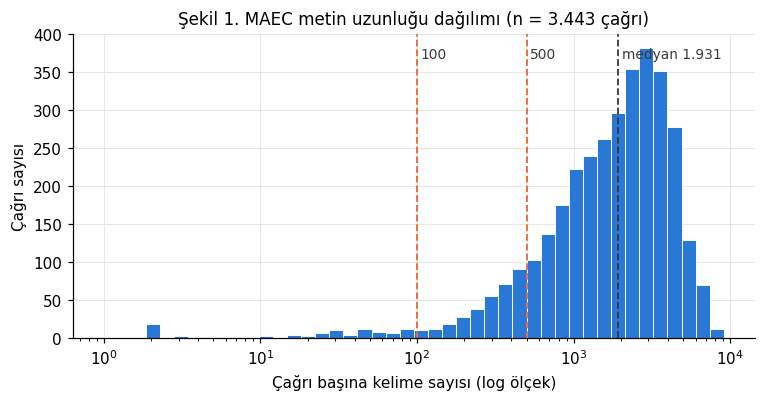

100 kelimeden kısa: 98 | 500 kelimeden kısa: 425
En fazla 5 kelimelik metin: 24 | metni yalnız 'Thank you.' olan: 19


In [5]:
fig, ax = plt.subplots(figsize=(8, 3.6))
kutular = np.logspace(0, np.log10(cagrilar.n_kelime.max() + 1), 45)
ax.hist(cagrilar.n_kelime.clip(lower=1), bins=kutular, color=MAVI, edgecolor="white", linewidth=0.6)
ax.set_xscale("log")
medyan = cagrilar.n_kelime.median()
for x, et in [(100, "100"), (500, "500"), (medyan, f"medyan {tr(medyan)}")]:
    ax.axvline(x, color=TURUNCU if x != medyan else KOYU, lw=1.2, ls="--")
    ax.text(x * 1.05, ax.get_ylim()[1] * 0.92, et, fontsize=9, color=KOYU)
ax.set_xlabel("Çağrı başına kelime sayısı (log ölçek)")
ax.set_ylabel("Çağrı sayısı")
ax.set_title("Şekil 1. MAEC metin uzunluğu dağılımı (n = 3.443 çağrı)")
kaydet(fig, "f1_01_metin_uzunlugu")
plt.show()
print("100 kelimeden kısa:", int((cagrilar.n_kelime < 100).sum()), "| 500 kelimeden kısa:", int((cagrilar.n_kelime < 500).sum()))
print("En fazla 5 kelimelik metin:", int((cagrilar.n_kelime <= 5).sum()), "| metni yalnız 'Thank you.' olan:",
      int(cagrilar.cumleler.apply(lambda s: s == ["Thank you."]).sum()))

**Ne gözlendi:** Çağrı, şirket, cümle sayısı ve tarih aralığı MAEC makalesinin Tablo 2'siyle birebir aynı. Yalnız token sayısı farklı: makale token sayma yöntemini vermiyor, biz boşlukla ayrılmış kelime sayıyoruz. Metin uzunluğu sola çarpık: medyan 1.931 kelime, %5'lik dilim 232; 98 çağrı 100 kelimeden, 425 çağrı 500 kelimeden kısa. 2 kelimedeki küçük tepe, metni yalnız "Thank you." olan 19 çağrıdır (en fazla 5 kelimelik metin: 24 çağrı). UTF-8 hatası ve boş dosya yok.

**Neden önemli:** Çok kısa metinlerde model o çağrı için neredeyse hiç metin bilgisi görmez; bu çağrılarda metin modalitesi fiilen eksiktir.

**Sonraki aşamaya etkisi:** Faz 2'de çok kısa metinler için bir eşik belirlenip öncesi–sonrası karşılaştırılacak. Uzun metinler (95. yüzdelik 5.127 kelime) metin kodlayıcısının girdi sınırı için kesme ya da parçalama gerektirecek.

**Gerçek örnek.** Aşağıda bir çağrının ilk ve son cümleleri var. Metnin bir cevabın ortasından başlaması ve analist
sorularının bulunmaması tesadüf değil: MAEC makalesi (Böl. 3.2–3.4) yalnız yönetim konuşmalarının (sunum ve soru-cevaptaki
yanıtlar) tutulduğunu, analist ve operatör konuşmalarının hizalama sırasında çıkarıldığını ve 0,7 saniyeden kısa
cümle-ses eşleşmelerinin atıldığını yazar.

In [6]:
def ornek_goster(klasor, bas=4, son=2):
    s = cagrilar.set_index("klasor").loc[klasor, "cumleler"]
    print(f"--- {klasor}: {len(s)} cümle ---")
    for x in s[:bas]:
        print("  ", textwrap.shorten(x, 150))
    print("   ...")
    for x in s[-son:]:
        print("  ", textwrap.shorten(x, 150))

ornek_goster("20150226_ACIW")
acilis = cagrilar[cagrilar.cumleler.apply(lambda s: bool(re.search(r"good (morning|afternoon)", " ".join(s[:3]), re.I)))]
ornek_goster(acilis.klasor.iloc[0])
print(f"\nİlk 3 cümlede 'good morning/afternoon' geçen çağrı: {len(acilis)} (%{100 * len(acilis) / len(cagrilar):.1f})")

--- 20150226_ACIW: 78 cümle ---
   I'm not in any way, shape or form -- I'm bad, we didn't sign it, but I don't feel bad about it in the least bit.
   To answer the -- I will let <UNK> answer the big part of the question, but we are EMV enabled both ways.
   We were really -- we didn't do that much EMV business last year.
   We spent all of the money to get everyone ready, we're SaaS enabled and whatnot, and we thought people come running in to try to go and protect [...]
   ...
   Thanks, everybody, for dialing in.
   We look forward to talking to you all in the next coming weeks.
--- 20150225_LMAT: 210 cümle ---
   Thank you, Whitley.
   Good afternoon and thank you for joining us on our Q4 2014 conference call.
   Joining me on today's call is our Chairman and CEO <UNK> <UNK> and our President <UNK> <UNK>.
   Before we begin, I will read our Safe Harbor statement.
   ...
   And, so, I think to your question, I think what you are seeing us try to do with the valvulotome, make a big c

**Ne gözlendi:** ACIW çağrısı bir cevabın ortasından başlıyor ve analist soruları yok; çağrıların yalnız %29,5'inin ilk üç cümlesinde "good morning/afternoon" geçiyor. Kişi adları 3.170 çağrıda `<UNK>` ile maskelenmiş.

**Neden önemli:** Metin tam transkript değil, "yönetimin söyledikleri"dir (MAEC makalesi, Böl. 3.2–3.4). Analistlerin soruları ve sunum ile soru-cevap ayrımı elimizde yok.

**Sonraki aşamaya etkisi:** Raporda metin modalitesi "yönetim konuşması" olarak tanımlanacak, soru-cevap ayrımının yapılamaması sınırlılık olarak yazılacak. Konuşmacı etiketi olan 2.388 çağrıda (Person1, Person2…) konuşmacı sayısı EDA'da incelenebilir.

## 3. Zaman serisi modalitesi: FNSPID envanteri (Kriter 2–3)

Her hisse için bir CSV: günlük `date, open, high, low, close, adj close, volume`. Oynaklık bölünme ve temettüye göre
düzeltilmiş kapanıştan (`adj close`) hesaplanır.

In [7]:
basliklar = Counter(fz.open(y).readline().decode("utf-8", "replace").strip() for y in fiyat_yollari.values())
print("Farklı sütun sırası sayısı:", len(basliklar))
display(pd.Series(basliklar, name="dosya sayısı").sort_values(ascending=False).to_frame())
ornek = veri.fiyat_oku(fiyat_yollari["ACIW"])
print("ACIW ham dosyada ilk satır tarihi:", pd.read_csv(fz.open(fiyat_yollari["ACIW"]), nrows=1)["date"].iloc[0],
      "→ dosyalar yeniden eskiye sıralı; okurken eskiden yeniye çevriliyor.")
ornek.head(3)

Farklı sütun sırası sayısı: 2


,dosya sayısı
"date,volume,open,high,low,close,adj close",5705
"date,open,high,low,close,adj close,volume",1988


ACIW ham dosyada ilk satır tarihi: 2023-12-28 → dosyalar yeniden eskiye sıralı; okurken eskiden yeniye çevriliyor.


,date,open,high,low,close,adj close,volume
0,1995-02-24,3.104167,3.104167,2.958333,2.979167,2.979167,18890400
1,1995-02-27,3.000000,3.083333,3.000000,3.041667,3.041667,2052600
2,1995-02-28,3.062500,3.062500,2.979167,2.979167,2.979167,3112800


**Ne gözlendi:** 7.693 hisse dosyası var. Dosyaların 5.705'inde sütun sırası `date, volume, open, …`, 1.988'inde `date, open, …, volume`. Tarihler yeniden eskiye sıralı; 73 dosya 200 bayttan küçük; zip'te ayrıca 7.694 macOS kopya dosyası var.

**Neden önemli:** Sütunları sıraya göre okumak hacim ile fiyatı karıştırır; ters sıralı tarihle getiri hesaplamak getirilerin işaretini tersine çevirir. İkisi de hata vermeden yanlış etiket üretirdi.

**Sonraki aşamaya etkisi:** Okuma kodu sütunları ada göre seçiyor ve tarihe göre sıralıyor (`src/veri.py`); bütün notebook'lar aynı fonksiyonu kullanıyor.

### Karşılaşılan sorunlar ve çözümleri (Kriter 2)

| Sorun | Etkisi olmasa ne olurdu | Çözüm |
|---|---|---|
| FNSPID zip'inde 7.694 `__MACOSX/._*` kopya dosyası | Sahte "hisse dosyaları" okunurdu | Yalnız `full_history/*.csv` okunur |
| İki farklı sütun sırası (5.705 / 1.988 dosya) | Hacim ile fiyat karışırdı | Sütunlar ada göre seçilir |
| Tarihler yeniden eskiye sıralı | Getirilerin işareti ters çıkardı | Okurken tarihe göre sıralanır |
| Kesik fiyat dosyaları (SON, SAFM tek satır; SPN, SJI geç başlıyor) | Eksik pencere | Düşme nedeni olarak kaydedilir (6 çağrı) |
| README'de anlatılmayan `MAEC_Dataset_Person_Label/` klasörü | — | Envantere alındı (2.388 çağrı); şimdilik kullanılmıyor |
| Metni yalnız "Thank you." olan 19 çağrı | Boş metin model girdisi olurdu | Faz 2'de ele alınacak |
| SEC, kimlik bildiren User-Agent ve en çok 10 istek/sn istiyor (sec.gov, "Accessing EDGAR Data") | İstek reddedilir | Kimlik `.env` dosyasından okunur, istekler arası 0,15 sn beklenir |
| SEC listesi güncel; 2015–2018'den beri borsadan çıkan şirketler yok | Ad/sektör bulunamaz | Eksik olarak raporlanır (eşleşen çağrıların %21,8'i) |
| Uzun indirme oturum kapanınca yarıda kalabiliyor | Baştan indirme | SEC yanıtları ve ham dosyalar önbelleğe yazılır; kod kaldığı yerden devam eder |

## 4. Modalite eşleştirme (Kriter 4)

**Anahtar:** `ticker` (MAEC klasör adındaki kod = FNSPID dosya adı, büyük harfe çevrilerek) + çağrı tarihi.
**İlişki:** bire bir (her çağrıya tek fiyat penceresi); bir şirketin birden çok çağrısı olabilir (bire çok şirket–çağrı).
**Zamansal kural:** olay günü **t0** = çağrı tarihine eşit ya da sonraki ilk işlem günü (en çok 5 takvim günü sonra).

```
gün:   -61 ......... -1 | 0 ........ +6 | +7 ... +10
       girdi: 60 getiri  | hedef: 7 getiri| yalnız grafik
```
Girdi gün −1 kapanışında biter, hedef gün 0'dan başlar: hiçbir gün iki tarafta birden yer almaz. Açılıştan önce (BMO)
yapılan çağrıda piyasa tepkisi gün 0'da, kapanıştan sonra (AMC) yapılanda gün +1'de görülür; ikisi de hedef penceresindedir.
**Sınırlılık:** AMC çağrılarında gün 0 getirisi çağrıdan önceki saatleri de içerir. Çağrı saati verisetinde yok.

In [8]:
durum, pencere = eslestir.tumunu_eslestir(cagrilar, fiyat_yollari)
eslesen = set(durum.loc[durum.durum == "eslesti", "klasor"])
sira = ["ticker fiyat verisinde yok", "fiyat dosyası boş", "fiyat serisi çağrı tarihini kapsamıyor",
        "çağrıdan sonra 5 gün içinde işlem günü yok", "60 günlük geçmiş yetersiz", "7 günlük gelecek yetersiz"]
kalan, satirlar = len(durum), [("MAEC çağrısı (başlangıç)", 0, len(durum))]
for n in sira:
    k = int((durum.durum == n).sum())
    kalan -= k
    satirlar.append((n, k, kalan))
dokum = pd.DataFrame(satirlar, columns=["adım", "düşen", "kalan"])
dokum["kalan_%"] = (100 * dokum.kalan / len(durum)).round(1)
assert dokum.kalan.iloc[-1] == len(eslesen)
display(dokum)
print("Eşleşen çağrı:", len(eslesen), "| şirket:", cagrilar[cagrilar.klasor.isin(eslesen)].ticker.nunique(),
      "| eşleşme oranı: %", round(100 * len(eslesen) / len(cagrilar), 1))
g = pencere[pencere.gun.between(-60, 6)]
print("Girdi/hedef penceresinde eksik getiri olan çağrı:", int(g.groupby("klasor").getiri.apply(lambda s: s.isna().any()).sum()))
t0_farki = (durum.dropna(subset=["t0"]).set_index("klasor").t0 - cagrilar.set_index("klasor").tarih).dropna().dt.days
print("Çağrı tarihi ile t0 arası (takvim günü):", t0_farki.value_counts().sort_index().to_dict())

,adım,düşen,kalan,kalan_%
0,MAEC çağrısı (başlangıç),0,3443,100.0
1,ticker fiyat verisinde yok,411,3032,88.1
2,fiyat dosyası boş,0,3032,88.1
3,fiyat serisi çağrı tarihini kapsamıyor,5,3027,87.9
4,çağrıdan sonra 5 gün içinde işlem günü yok,0,3027,87.9
5,60 günlük geçmiş yetersiz,1,3026,87.9
6,7 günlük gelecek yetersiz,0,3026,87.9


Eşleşen çağrı: 3026 | şirket: 1055 | eşleşme oranı: % 87.9
Girdi/hedef penceresinde eksik getiri olan çağrı: 0


Çağrı tarihi ile t0 arası (takvim günü): {0: 3026}


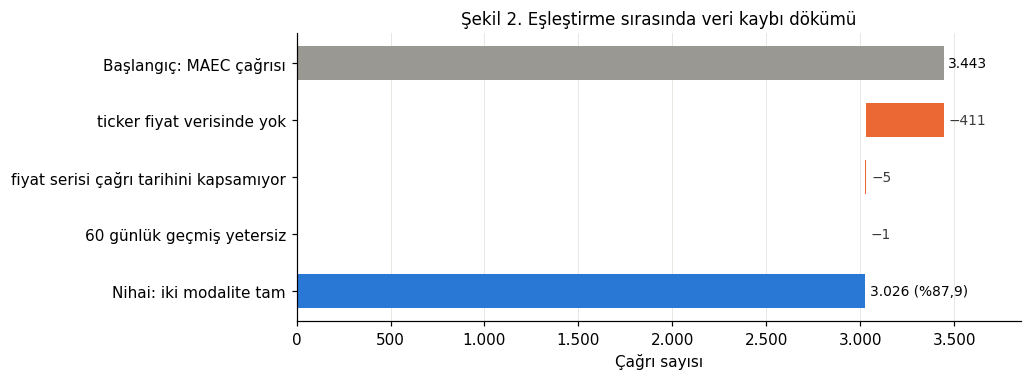

In [9]:
fig, ax = plt.subplots(figsize=(8.5, 3.4))
dusen = dokum[dokum.düşen > 0]
etiketler = ["Başlangıç: MAEC çağrısı"] + list(dusen["adım"]) + ["Nihai: iki modalite tam"]
y = np.arange(len(etiketler))
ax.barh(y[0], len(durum), color=GRI, height=0.6)
onceki = len(durum)
for i, r in enumerate(dusen.itertuples(), start=1):
    ax.barh(y[i], r.düşen, left=onceki - r.düşen, color=TURUNCU, height=0.6)
    ax.text(onceki + 25, y[i], f"−{tr(r.düşen)}", va="center", fontsize=9, color=KOYU)
    onceki -= r.düşen
ax.barh(y[-1], onceki, color=MAVI, height=0.6)
ax.text(len(durum) + 25, y[0], tr(len(durum)), va="center", fontsize=9)
ax.text(onceki + 25, y[-1], f"{tr(onceki)} (%{tr(100 * onceki / len(durum), 1)})", va="center", fontsize=9)
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: tr(x)))
ax.set_yticks(y, etiketler)
ax.invert_yaxis()
ax.set_xlim(0, len(durum) * 1.12)
ax.set_xlabel("Çağrı sayısı")
ax.set_title("Şekil 2. Eşleştirme sırasında veri kaybı dökümü")
ax.grid(axis="y", visible=False)
kaydet(fig, "f1_02_veri_kaybi")
plt.show()

**Ne gözlendi:** 3.443 çağrının 3.026'sı (%87,9; 1.055 şirket) iki modaliteyle eşleşti. Kaybın neredeyse tamamı (411 çağrı) ticker'ın FNSPID'de hiç olmamasından. 6 çağrı kesik fiyat dosyası yüzünden düştü (SON ve SAFM dosyaları tek satır, SPN 2019'da, SJI 2015-01-02'de başlıyor). Eşleşen çağrıların hepsinde çağrı tarihi bir işlem günü (t0 = çağrı tarihi); girdi ve hedef pencerelerinde eksik getiri yok.

**Neden önemli:** Kayıp rastgele değilse örneklem yanlı olur; bu, 4.1'de inceleniyor.

**Sonraki aşamaya etkisi:** Nihai veri 3.026 çağrı. Düşen 417 çağrı ve nedenleri `cikti/f1_veri_kaybi_dokumu.csv` dosyasında.

### 4.1 Eşleşmeyen çağrılar: neden?

In [10]:
sirket = sec.sirket_bilgisi(cagrilar.ticker.unique()).set_index("ticker")
c2 = cagrilar.merge(durum, on="klasor")
c2["eslesti"] = c2.durum == "eslesti"
yil = c2.assign(yil=c2.tarih.dt.year).groupby("yil").eslesti.agg(cagri="size", eslesen="sum")
yil["eşleşmeyen_%"] = (100 * (1 - yil.eslesen / yil.cagri)).round(1)
display(yil)

es_t = set(c2.loc[c2.eslesti, "ticker"])
yok_t = sorted(set(c2.ticker) - es_t)
print(f"Hiç eşleşmeyen şirket: {len(yok_t)} | bunlardan SEC'in GÜNCEL listesinde olan: "
      f"{int(sirket.loc[yok_t].cik.notna().sum())} | eşleşen {len(es_t)} şirketten SEC'te olan: {int(sirket.loc[sorted(es_t)].cik.notna().sum())}")
print(f"  ↳ ticker'ı FNSPID'de hiç olmayan: {sum(t not in fiyat_yollari for t in yok_t)} | dosyası olup kesik olan: "
      f"{sum(t in fiyat_yollari for t in yok_t)} ({', '.join(t for t in yok_t if t in fiyat_yollari)})")
print("Örnek eşleşmeyen kodlar:", ", ".join(yok_t[:30]))

kesik = c2[c2.durum.isin(["fiyat serisi çağrı tarihini kapsamıyor", "60 günlük geçmiş yetersiz"])]
satirlar = []
for r in kesik.itertuples():
    p = veri.fiyat_oku(fiyat_yollari[r.ticker])
    satirlar.append({"klasor": r.klasor, "neden": r.durum, "dosya_satir": len(p),
                     "dosya_ilk_tarih": p.date.min().date(), "dosya_son_tarih": p.date.max().date()})
pd.DataFrame(satirlar)

,cagri,eslesen,eşleşmeyen_%
yil,,,
2015,765,666,12.9
2016,1400,1220,12.9
2017,958,862,10.0
2018,320,278,13.1


Hiç eşleşmeyen şirket: 158 | bunlardan SEC'in GÜNCEL listesinde olan: 42 | eşleşen 1055 şirketten SEC'te olan: 824
  ↳ ticker'ı FNSPID'de hiç olmayan: 155 | dosyası olup kesik olan: 3 (SAFM, SON, SPN)
Örnek eşleşmeyen kodlar: ABAX, ACET, ACXM, AET, AHL, AKS, ALOG, ANDV, APC, ARRS, BBT, BEL, BGC, BID, BKS, BMS, BOBE, BRS, CA, CB, CBG, CBM, CECO, CELG, CHCT, CHFC, CHSP, CLD, COL, CPLA


,klasor,neden,dosya_satir,dosya_ilk_tarih,dosya_son_tarih
0,20150227_SJI,60 günlük geçmiş yetersiz,1385,2015-01-02,2020-07-02
1,20160211_SON,fiyat serisi çağrı tarihini kapsamıyor,1,2020-07-02,2020-07-02
2,20160421_SON,fiyat serisi çağrı tarihini kapsamıyor,1,2020-07-02,2020-07-02
3,20160526_SAFM,fiyat serisi çağrı tarihini kapsamıyor,1,2020-07-02,2020-07-02
4,20161025_SPN,fiyat serisi çağrı tarihini kapsamıyor,131,2019-12-26,2020-07-02
5,20170223_SAFM,fiyat serisi çağrı tarihini kapsamıyor,1,2020-07-02,2020-07-02


**Ne gözlendi:** Eşleşmeme oranı yıllara göre benzer (%10,0–13,1); zamana bağlı bir kopukluk yok. Ama eşleşmeyen 158 şirketin (155'i FNSPID'de hiç yok, 3'ünün dosyası kesik) yalnız 42'si SEC'in bugünkü listesinde; eşleşen şirketlerde bu sayı 1.055'te 824. Eşleşmeyen kodların çoğu bugün işlem görmüyor (olası nedenler satın alma, birleşme ya da kod değişikliği; şirket bazında tek tek doğrulanmadı).

**Neden önemli:** Bu bir hayatta kalma (survivorship) yanlılığıdır: veri, sonradan borsadan çıkan şirketleri eksik temsil eder; bu şirketlerin çağrı sonrası oynaklığı farklı olabilir.

**Sonraki aşamaya etkisi:** Raporda sınırlılık olarak yazılacak. Gidermek, kalıcı menkul kıymet kimliği olan lisanslı bir veri kaynağı gerektirir; bu projenin kapsamı dışında.

### 4.2 Doğru eşleşmenin kanıtı 1: olay günü sıçraması

Tarihler doğru eşleştiyse, kazanç açıklaması etrafında (gün 0 ve +1) mutlak getiri, sıradan günlere göre belirgin biçimde
artmalıdır. Tarihler kaymış olsaydı bu sıçrama görülmezdi.

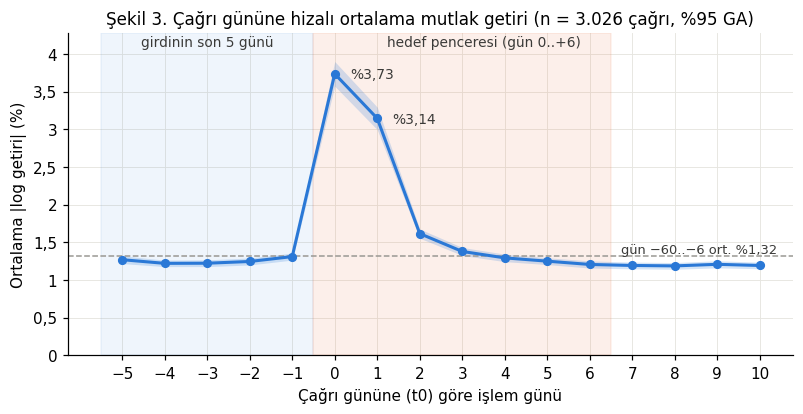

{-5: 1.27, -4: 1.22, -3: 1.22, -2: 1.24, -1: 1.31, 0: 3.73, 1: 3.14, 2: 1.61, 3: 1.38, 4: 1.29, 5: 1.25, 6: 1.2, 7: 1.19, 8: 1.19, 9: 1.21, 10: 1.19}
Sıradan günler (gün −60..−6) ortalama |getiri|: %1.32
|r0| > |r+1| olan çağrı oranı: %56.5  (BMO ağırlıklı tepki göstergesi)


In [11]:
a = pencere[pencere.gun.between(-5, 10)].assign(mutlak=lambda x: 100 * x.getiri.abs())
ozet_g = a.groupby("gun").mutlak.agg(["mean", "std", "count"])
ozet_g["yarim_ga"] = 1.96 * ozet_g["std"] / np.sqrt(ozet_g["count"])
normal = 100 * pencere[pencere.gun.between(-60, -6)].getiri.abs().mean()

fig, ax = plt.subplots(figsize=(8.5, 3.8))
ax.axvspan(-5.5, -0.5, color=MAVI, alpha=0.07)
ax.axvspan(-0.5, 6.5, color=TURUNCU, alpha=0.10)
ust = ozet_g["mean"].max() * 1.10
ax.set_ylim(top=ust * 1.04)
ax.text(-3, ust, "girdinin son 5 günü", ha="center", fontsize=9, color=KOYU)
ax.text(3.5, ust, "hedef penceresi (gün 0..+6)", ha="center", fontsize=9, color=KOYU)
ax.axhline(normal, color=GRI, lw=1, ls="--")
ax.text(10.4, normal, f"gün −60..−6 ort. %{tr(normal, 2)}", va="bottom", ha="right", fontsize=8.5, color=KOYU)
ax.fill_between(ozet_g.index, ozet_g["mean"] - ozet_g.yarim_ga, ozet_g["mean"] + ozet_g.yarim_ga, color=MAVI, alpha=0.2, lw=0)
ax.plot(ozet_g.index, ozet_g["mean"], color=MAVI, lw=2, marker="o", ms=5)
for gun in (0, 1):
    ax.annotate(f"%{tr(ozet_g.loc[gun, 'mean'], 2)}", (gun, ozet_g.loc[gun, "mean"]), textcoords="offset points",
                xytext=(10, -3), fontsize=9, color=KOYU)
ax.yaxis.set_major_formatter(VIRGUL)
ax.set_xticks(range(-5, 11))
ax.set_xlabel("Çağrı gününe (t0) göre işlem günü")
ax.set_ylabel("Ortalama |log getiri| (%)")
ax.set_title(f"Şekil 3. Çağrı gününe hizalı ortalama mutlak getiri (n = {tr(ozet_g['count'].min())} çağrı, %95 GA)")
kaydet(fig, "f1_03_olay_gunu")
plt.show()

piv = a.pivot(index="klasor", columns="gun", values="mutlak")
print(ozet_g["mean"].round(2).to_dict())
print(f"Sıradan günler (gün −60..−6) ortalama |getiri|: %{normal:.2f}")
print(f"|r0| > |r+1| olan çağrı oranı: %{100 * (piv[0] > piv[1]).mean():.1f}  (BMO ağırlıklı tepki göstergesi)")

**Ne gözlendi:** Sıradan günlerde (gün −60..−6) ortalama mutlak getiri %1,32. Gün 0'da %3,73'e, gün +1'de %3,14'e çıkıyor; gün +2'de %1,61 ve sonra hızla normale dönüyor. Güven aralıkları dar. Çağrıların %56,5'inde gün 0 tepkisi gün +1'den büyük.

**Neden önemli:** (1) Tarihler doğru eşleşmiş: kaymış olsaydı sıçrama bu iki güne yığılmazdı. (2) Tepki hem gün 0'da (açılış öncesi çağrılar) hem gün +1'de (kapanış sonrası çağrılar) görülüyor; hedef penceresi (gün 0..+6) ikisini de kapsıyor. Bu, Berkman ve Truong'un (2009) kapanış sonrası duyurularda tepkinin bir işlem günü sonra görüldüğü bulgusuyla tutarlı. (3) Girdinin son günü (gün −1) normal seviyede: girdiye sızan bir tepki yok.

**Sonraki aşamaya etkisi:** Sınırlılık: kapanış sonrası çağrılarda gün 0 getirisi çağrı öncesi saatleri de içerir; çağrı saati veride olmadığı için bu ayrım yapılamıyor.

### 4.3 Doğru eşleşmenin kanıtı 2: transkriptte şirket adı geçiyor mu?

Kişi adları maskeli ama şirket adları açık. SEC EDGAR'dan ticker → şirket adı (ve eski adları) alınır. Bir çağrı
"adı geçiyor" sayılır, eğer transkriptte (a) adın yaygın olmayan bir kelimesi (≥ 4 harf; Inc, Corp, Financial, Systems
gibi ekler ve sık iş kelimeleri hariç) ya da (b) büyük harfle şirketin kısaltması (ticker ya da adın baş harfleri; ≥ 3 harf,
ör. ADP) geçiyorsa. Aksanlar ve kesme işaretleri temizlenir (Estée → estee, Kohl's → kohls).

**Karşılaştırma (yanlış eşleşme taban oranı):** Aynı kontrol, her çağrıya *başka bir şirketin* adı verilerek tekrarlanır.
Doğru eşleşmede oran yüksek, yanlış eşleşmede düşük olmalıdır. Kontrol sezgiseldir: yöneticiler kendi şirketlerini çoğu
zaman "we" diye anar, metin de yalnız yönetim konuşmasından oluşur; bu yüzden adın geçmemesi tek başına hata değildir.

In [12]:
import unicodedata

EKLER = {"inc", "incorporated", "corp", "corporation", "co", "company", "companies", "ltd", "limited", "plc", "holding",
         "holdings", "group", "the", "lp", "llc", "trust", "nv", "sa", "de", "new", "com", "and"}
YAYGIN = {"american", "first", "united", "general", "national", "international", "southern", "western", "eastern",
          "northern", "great", "global", "energy", "financial", "bank", "banks", "bancorp", "bancshares", "community",
          "home", "homes", "capital", "federal", "pacific", "atlantic", "central", "universal", "standard", "applied",
          "advanced", "royal", "data", "processing", "systems", "services", "service", "solutions", "resources",
          "industries", "industrial", "products", "technologies", "technology", "communications", "health",
          "healthcare", "care", "medical", "pharmaceuticals", "therapeutics", "insurance", "partners", "properties",
          "realty", "management", "brands", "foods", "food", "stores", "entertainment", "networks", "software",
          "enterprises", "investment", "investors", "power", "electric", "water", "mining", "materials", "chemical",
          "chemicals", "steel", "motors", "automotive", "airlines", "logistics", "media", "business", "market",
          "markets", "real", "estate", "growth", "street", "light", "life", "world", "west", "east", "north", "south",
          "city", "state", "valley", "river", "union", "people", "peoples", "security", "securities", "office",
          "group", "works", "design", "devices", "instruments", "sciences", "science", "labs", "laboratories",
          "restaurants", "hotels", "resorts", "gold", "silver", "mobile", "digital", "online", "interactive"}


def sade(s):
    s = unicodedata.normalize("NFKD", s).encode("ascii", "ignore").decode().lower().replace("'", "").replace("’", "")
    return re.sub(r"[^a-z0-9]+", " ", s).split()


def isaretler(ticker):
    """Bir şirket için aranacak işaretler: ad kelimeleri (küçük harf) ve büyük harfli kısaltmalar."""
    adlar = [sirket.loc[ticker, "ad"]] + list(sirket.loc[ticker, "eski_adlar"])
    kelime, kisalt = set(), ({ticker.upper()} if len(ticker) >= 3 else set())
    for ad in adlar:
        k = [x for x in sade(re.sub(r"/[A-Za-z]{2,3}/?", " ", ad)) if x not in EKLER]
        kelime |= {x for x in k if len(x) >= 4 and x not in YAYGIN}
        bas = "".join(x[0] for x in k if not x.isdigit()).upper()
        if len(bas) >= 3:
            kisalt.add(bas)
    return kelime, kisalt


es = cagrilar[cagrilar.klasor.isin(eslesen)].copy()
es = es[es.ticker.map(sirket.cik).notna()].sort_values(["ticker", "tarih"]).reset_index(drop=True)
metin_kelime = [set(sade(" ".join(s))) for s in es.cumleler]
metin_buyuk = [set(re.findall(r"\b[A-Z]{3,6}\b", " ".join(s))) for s in es.cumleler]
isaret = {t: isaretler(t) for t in es.ticker.unique()}


def gecme(tickerlar):
    return np.array([bool(isaret[t][0] & mk) or bool(isaret[t][1] & mb) for t, mk, mb in zip(tickerlar, metin_kelime, metin_buyuk)])


es["ad_geciyor"] = gecme(es.ticker)
baska = np.roll(es.ticker.to_numpy(), 500)   # ticker'a göre sıralı listede 500 kaydırma → her çağrıya başka bir şirketin adı
assert (baska != es.ticker.to_numpy()).all()
yanlis = gecme(baska)
print(f"Eşleşmiş çağrıdan SEC adı bulunan: {len(es):,} / {len(eslesen):,}")
print(f"Kendi şirket adı transkriptte geçen: {es.ad_geciyor.sum():,} (%{100 * es.ad_geciyor.mean():.1f})")
print(f"BAŞKA bir şirketin adı geçen (yanlış eşleşme taban oranı): {yanlis.sum():,} (%{100 * yanlis.mean():.1f})")
print(f"Oran: {es.ad_geciyor.mean() / yanlis.mean():.1f} kat | SEC adı olmadığı için kontrol edilemeyen eşleşmiş çağrı: {len(eslesen) - len(es)}")
gecmeyen = es[~es.ad_geciyor]
print(f"Kendi adı geçmeyen {len(gecmeyen)} çağrının medyan kelime sayısı: {gecmeyen.n_kelime.median():.0f} "
      f"(geçenlerde {es[es.ad_geciyor].n_kelime.median():.0f})")
gecmeyen.assign(sec_adi=gecmeyen.ticker.map(sirket.ad))[["klasor", "sec_adi", "n_kelime"]].sort_values(
    "n_kelime", ascending=False).head(10)

Eşleşmiş çağrıdan SEC adı bulunan: 2,367 / 3,026
Kendi şirket adı transkriptte geçen: 1,517 (%64.1)
BAŞKA bir şirketin adı geçen (yanlış eşleşme taban oranı): 87 (%3.7)
Oran: 17.4 kat | SEC adı olmadığı için kontrol edilemeyen eşleşmiş çağrı: 659
Kendi adı geçmeyen 850 çağrının medyan kelime sayısı: 1118 (geçenlerde 2393)


,klasor,sec_adi,n_kelime
254,20170419_AXP,AMERICAN EXPRESS CO,6381
871,20171025_GD,GENERAL DYNAMICS CORP,5652
1294,20171024_LMT,LOCKHEED MARTIN CORP,5495
596,20150506_DDD,3D SYSTEMS CORP,5483
687,20170426_ECHO,EchoStar CORP,5445
372,20150420_CBU,"COMMUNITY FINANCIAL SYSTEM, INC.",5345
671,20160824_DY,DYCOM INDUSTRIES INC,5168
869,20170127_GD,GENERAL DYNAMICS CORP,5158
376,20180425_CBU,"COMMUNITY FINANCIAL SYSTEM, INC.",5081
327,20171116_BRC,BRADY CORP,5059


**Ne gözlendi:** SEC adı bulunan 2.367 eşleşmiş çağrının %64,1'inde şirketin kendi adı ya da kısaltması transkriptte geçiyor; her çağrıya başka bir şirketin adı verildiğinde bu oran %3,7. Adı geçmeyen çağrılar belirgin biçimde kısa (medyan 1.118 kelimeye karşı 2.393).

**Neden önemli:** Doğru ve yanlış eşleşme arasındaki yaklaşık 17 kat fark, ticker + tarih eşleştirmesinin doğru şirketi bulduğunu gösteriyor. Adın geçmemesi çoğunlukla metnin kısa olmasından ve yöneticilerin şirketten "we" diye söz etmesinden kaynaklanıyor (ör. JPMorgan çağrısında ad hiç geçmiyor).

**Sonraki aşamaya etkisi:** Ad geçmediği için hiçbir çağrı çıkarılmıyor; bu kontrol rapordaki eşleşme kanıtlarından biri. Şirketi SEC'in güncel listesinde olmayan 659 çağrıda kontrol yapılamadı.

### 4.4 Doğru eşleşmenin kanıtı 3: gerçek örnekler (aynı olayın iki modalitesi)

Her sınıftan, hedef oynaklığı sınıf medyanına en yakın ve adı transkriptte geçen bir çağrı seçildi (seçim kuralı
koddadır, elle seçim yok). Sol: t0'a göre hizalı fiyat (gün −1 = 100); sağ: aynı çağrının transkriptinden ilk cümleler.

Eşikler (log std): [-4.1445 -3.6096] → günlük getiri std'si: % [1.585 2.706]


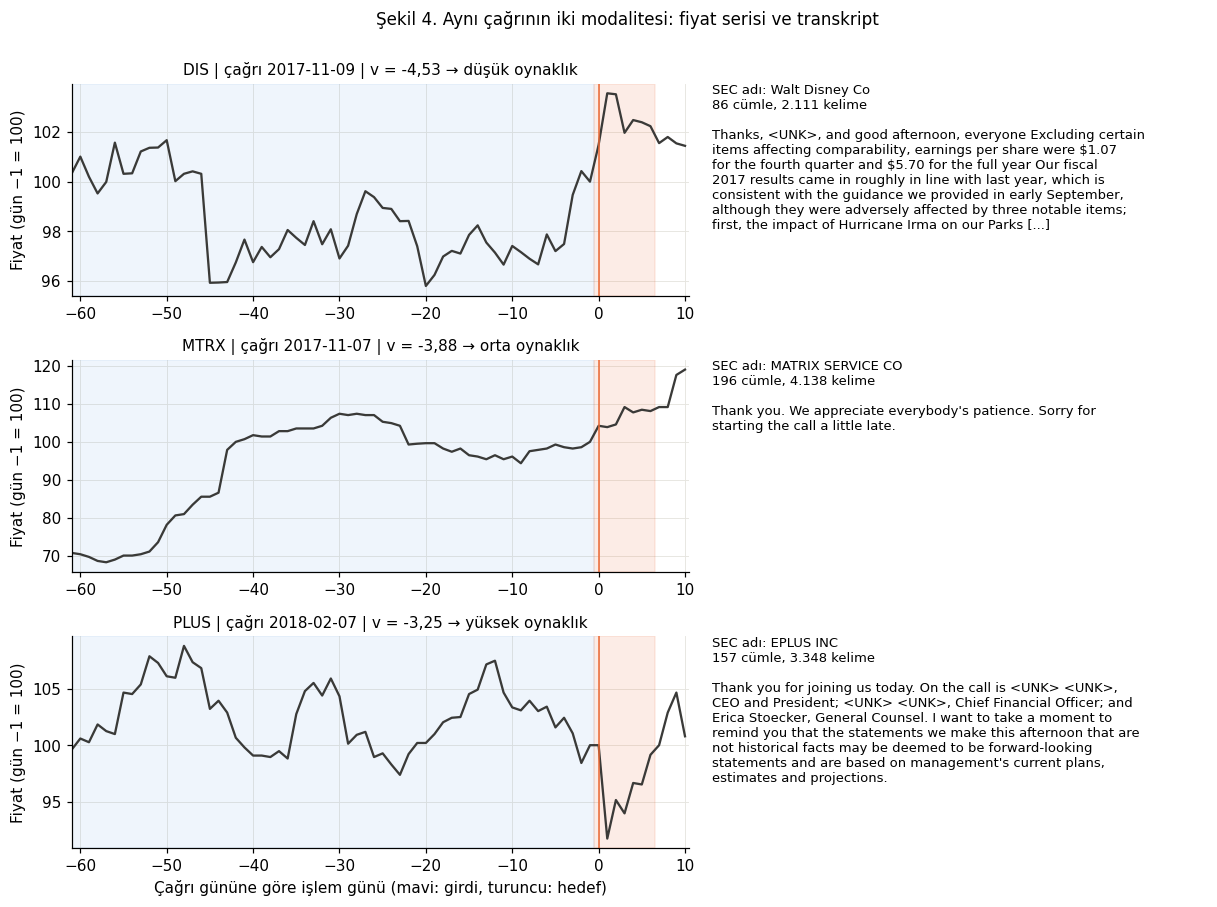

In [13]:
v = etiket.hedef_oynaklik(pencere)
tablo = cagrilar.set_index("klasor").loc[v.index, ["tarih", "ticker", "n_cumle", "n_kelime", "konusmaci_etiketi"]].assign(v=v)
tablo["t0"] = durum.set_index("klasor").loc[v.index, "t0"]
egitim = (tablo.tarih <= "2016-12-31").to_numpy()
esik = etiket.esikler(tablo.v[egitim])
tablo["sinif"] = etiket.siniflandir(tablo.v, esik).astype(int)
tablo["ad_geciyor"] = es.set_index("klasor").ad_geciyor
print("Eşikler (log std):", np.round(esik, 4), "→ günlük getiri std'si: %", np.round(100 * np.exp(esik), 3))

ornekler = []
for c in range(3):
    aday = tablo[(tablo.sinif == c) & (tablo.ad_geciyor == True) & (tablo.n_kelime >= 800)]
    ornekler.append((aday.v - tablo[tablo.sinif == c].v.median()).abs().idxmin())

fig, eksen = plt.subplots(3, 2, figsize=(11.5, 8.2), gridspec_kw={"width_ratios": [1.25, 1]})
for (sol, sag), k in zip(eksen, ornekler):
    r = tablo.loc[k]
    p = pencere[pencere.klasor == k].set_index("gun")["adj close"]
    p = 100 * p / p.loc[-1]
    sol.axvspan(-61, -0.5, color=MAVI, alpha=0.07)
    sol.axvspan(-0.5, 6.5, color=TURUNCU, alpha=0.12)
    sol.plot(p.index, p.values, color=KOYU, lw=1.5)
    sol.axvline(0, color=TURUNCU, lw=1)
    sol.set_xlim(-61, 10.5)
    sol.set_title(f"{r.ticker} | çağrı {r.tarih.date()} | v = {tr(r.v, 2)} → {etiket.SINIF_ADLARI[r.sinif]} oynaklık", fontsize=10)
    sol.set_ylabel("Fiyat (gün −1 = 100)")
    sag.axis("off")
    cumle = " ".join(cagrilar.set_index("klasor").loc[k, "cumleler"][:3])
    sag.text(0, 1, f"SEC adı: {sirket.loc[r.ticker, 'ad']}\n{tr(r.n_cumle)} cümle, {tr(r.n_kelime)} kelime\n\n"
             + textwrap.fill(textwrap.shorten(cumle, 430), 62), va="top", fontsize=8.6, family="DejaVu Sans")
eksen[-1][0].set_xlabel("Çağrı gününe göre işlem günü (mavi: girdi, turuncu: hedef)")
fig.suptitle("Şekil 4. Aynı çağrının iki modalitesi: fiyat serisi ve transkript", y=1.0, fontsize=11)
fig.tight_layout()
kaydet(fig, "f1_04_eslesme_ornekleri")
plt.show()

**Ne gözlendi:** Üç örnekte de fiyat serisi ve transkript aynı olaya ait: Walt Disney (DIS) yönetimi çeyrek sonuçlarını açıklıyor ve çağrı sonrası küçük bir sıçramanın ardından fiyat sakin seyrediyor (düşük sınıf); ePlus (PLUS) çağrısından sonra fiyat sert düşüyor ve dalgalı seyrediyor (yüksek sınıf). Örnekler bir kuralla seçildi: her sınıfta hedef oynaklığı sınıf medyanına en yakın çağrı.

**Neden önemli:** Kriter 4'ün istediği, gerçek örnek üzerinde doğru eşleşmenin görsel kanıtı. Ayrıca iki modalitenin aynı olayın farklı yüzlerini taşıdığını gösteriyor: fiyat çağrı öncesi seyri, metin yönetimin açıkladığı içeriği.

**Sonraki aşamaya etkisi:** Etik notu: PLUS örneğinde bir yöneticinin adı maskelenmemiş; MAEC'in ad maskelemesi her yerde tam değil. Raporda bu not yer alacak.

### 4.5 Zaman serisi uzunluğu ve takvim tutarlılığı

Model girdisi her çağrı için sabit uzunlukta (60 getiri). Burada iki şey ölçülür: (a) fiyat dosyasında t0'dan önce kaç
işlem günü var (60 şartı ne kadar rahat karşılanıyor), (b) 61 günlük girdi penceresi SPY'nin (piyasa fonu) işlem günü
takvimiyle karşılaştırıldığında eksik gün var mı.

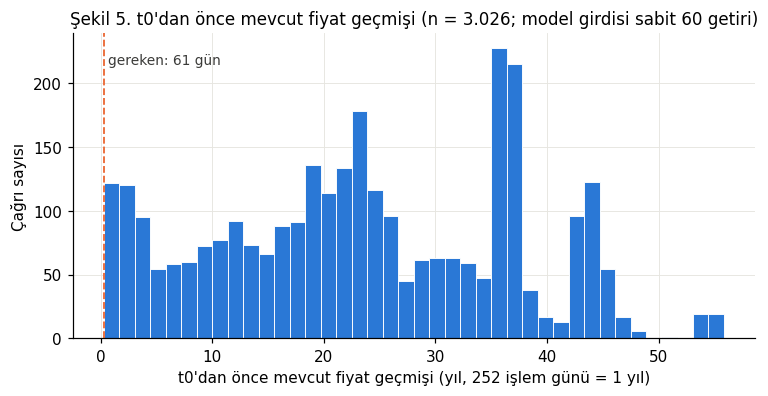

t0 öncesi geçmiş (işlem günü) özet: {'count': 3026.0, 'mean': 5921.0, 'std': 3365.0, 'min': 65.0, '25%': 3237.0, '50%': 5786.0, '75%': 8978.0, 'max': 14070.0}
Medyan geçmiş ≈ 23.0 yıl (252 işlem günü = 1 yıl)
Girdi penceresinde eksik gün dağılımı: {0: 3026}
Hedef penceresinde eksik gün dağılımı: {0: 3026}


In [14]:
spy = veri.fiyat_oku(fiyat_yollari["SPY"])["date"].to_numpy()
uc = pencere[pencere.gun.isin([-61, -1, 0, 6])].pivot(index="klasor", columns="gun", values="date")


def piyasa_gunu(bas, son):
    return np.searchsorted(spy, son.to_numpy(), side="right") - np.searchsorted(spy, bas.to_numpy(), side="left")


uc["girdi_eksik_gun"] = piyasa_gunu(uc[-61], uc[-1]) - 61
uc["hedef_eksik_gun"] = piyasa_gunu(uc[0], uc[6]) - 7
gecmis = durum.set_index("klasor").loc[list(eslesen), "t0_oncesi_gun"].astype(int)

fig, a1 = plt.subplots(figsize=(8, 3.6))
a1.hist(gecmis / 252, bins=40, color=MAVI, edgecolor="white", linewidth=0.6)
a1.axvline(61 / 252, color=TURUNCU, lw=1.2, ls="--")
a1.text(61 / 252 + 0.4, a1.get_ylim()[1] * 0.9, "gereken: 61 gün", fontsize=9, color=KOYU)
a1.set_xlabel("t0'dan önce mevcut fiyat geçmişi (yıl, 252 işlem günü = 1 yıl)")
a1.set_ylabel("Çağrı sayısı")
a1.set_title(f"Şekil 5. t0'dan önce mevcut fiyat geçmişi (n = {tr(len(gecmis))}; model girdisi sabit 60 getiri)")
kaydet(fig, "f1_05_seri_uzunlugu")
plt.show()
print("t0 öncesi geçmiş (işlem günü) özet:", gecmis.describe().round(0).to_dict())
print(f"Medyan geçmiş ≈ {gecmis.median() / 252:.1f} yıl (252 işlem günü = 1 yıl)")
print("Girdi penceresinde eksik gün dağılımı:", uc.girdi_eksik_gun.value_counts().sort_index().to_dict())
print("Hedef penceresinde eksik gün dağılımı:", uc.hedef_eksik_gun.value_counts().sort_index().to_dict())

**Ne gözlendi:** Her eşleşen çağrı için t0'dan önce en az 65 işlem günü fiyat var (medyan 5.786 gün, yaklaşık 23 yıl); 61 günlük gereksinimi yalnız 1 çağrı (SJI) karşılayamadı. SPY işlem takvimine göre 61 günlük girdi ve 7 günlük hedef pencerelerinin hiçbirinde eksik gün yok.

**Neden önemli:** Model girdisi her çağrı için aynı uzunlukta (60 günlük getiri dizisi) ve takvimle hizalı; dolgu (padding) ya da boşluk doldurma gerekmiyor.

**Sonraki aşamaya etkisi:** Uzun geçmiş, istenirse daha uzun girdi pencereleriyle deneme yapmaya izin veriyor; ana tasarım 60 günde kalıyor.

## 5. Hedef etiket ve kalitesi (Kriter 4)

**Köken:** Etiket elle verilmez; fiyattan hesaplanır. Oynaklık $v = \ln\big(\mathrm{std}(r_0,\dots,r_{+6})\big)$,
$r_t = \ln(P_t / P_{t-1})$, $P$ = düzeltilmiş kapanış, std paydası 7. Sınıflar: eğitim kısmındaki (çağrı tarihi
≤ 2016-12-31) $v$ değerlerinin 1/3 ve 2/3 kantilleri eşik → düşük / orta / yüksek. Her fold'un kendi eşikleri Faz 4'te.

**Literatürle ilişki:** Tanım Kogan vd. (2009) ve Qin ve Yang (2019)'daki log-oynaklığa *yakındır ama birebir aynı değildir*:
Qin ve Yang basit getiri ve **takvim günü** kullanır ve çağrı gününün pencereye dahil olup olmadığını açıkça yazmaz.

In [15]:
siniflar = pd.DataFrame({
    "tümü": tablo.sinif.value_counts().sort_index(),
    "eğitim (≤2016)": tablo[egitim].sinif.value_counts().sort_index(),
    "sonrası (2017–2018)": tablo[~egitim].sinif.value_counts().sort_index(),
}).rename(index=dict(enumerate(etiket.SINIF_ADLARI)))
siniflar.loc["toplam"] = siniflar.sum()
display(siniflar)
display((100 * siniflar.iloc[:3] / siniflar.iloc[3]).round(1).rename(columns=lambda c: c + " %"))
n_sinif, en_az, toplam = (siniflar.iloc[:3, 0] > 0).sum(), int(siniflar.iloc[:3, 0].min()), int(siniflar.iloc[3, 0])
print(f"Ders şartı → sınıf sayısı {n_sinif} ≥ 3: {n_sinif >= 3} | en küçük sınıf {en_az} ≥ 150: {en_az >= 150} | toplam {toplam} ≥ 500: {toplam >= 500}")

,tümü,eğitim (≤2016),sonrası (2017–2018)
sinif,,,
düşük,1081,629,452
orta,948,628,320
yüksek,997,629,368
toplam,3026,1886,1140


,tümü %,eğitim (≤2016) %,sonrası (2017–2018) %
sinif,,,
düşük,35.7,33.4,39.6
orta,31.3,33.3,28.1
yüksek,32.9,33.4,32.3


Ders şartı → sınıf sayısı 3 ≥ 3: True | en küçük sınıf 948 ≥ 150: True | toplam 3026 ≥ 500: True


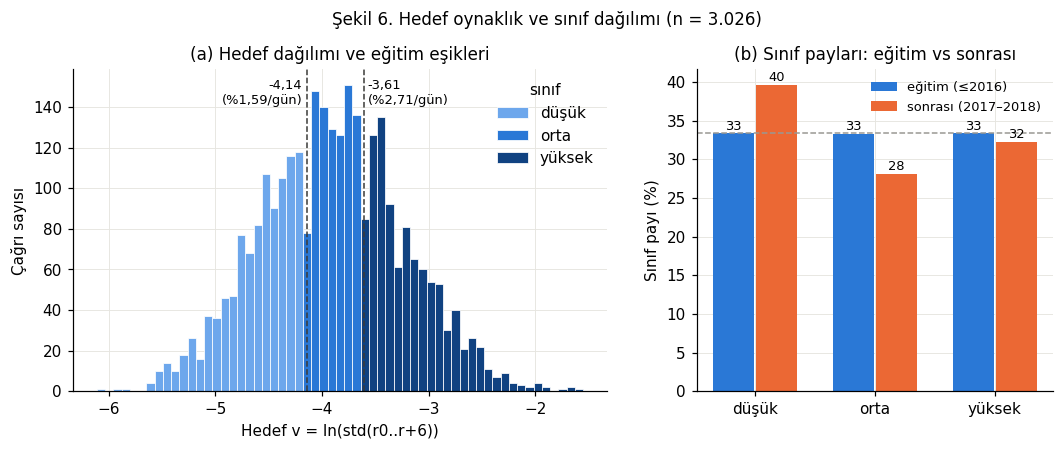

In [16]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11.5, 3.8), gridspec_kw={"width_ratios": [1.5, 1]})
kutular = np.linspace(tablo.v.min(), tablo.v.max(), 60)
for c in range(3):
    a1.hist(tablo.v[tablo.sinif == c], bins=kutular, color=SINIF_RENK[c], edgecolor="white", linewidth=0.5,
            label=etiket.SINIF_ADLARI[c])
for i, e in enumerate(esik):
    a1.axvline(e, color=KOYU, lw=1, ls="--")
    a1.text(e + (-0.04 if i == 0 else 0.04), a1.get_ylim()[1] * 0.97, f"{tr(e, 2)}\n(%{tr(100 * np.exp(e), 2)}/gün)",
            fontsize=8.5, va="top", ha="right" if i == 0 else "left")
a1.set_xlabel("Hedef v = ln(std(r0..r+6))")
a1.set_ylabel("Çağrı sayısı")
a1.legend(title="sınıf", frameon=False)
a1.set_title("(a) Hedef dağılımı ve eğitim eşikleri")
x = np.arange(3)
for j, (kol, renk) in enumerate([("eğitim (≤2016)", MAVI), ("sonrası (2017–2018)", TURUNCU)]):
    pay = 100 * siniflar[kol].iloc[:3] / siniflar[kol].iloc[3]
    a2.bar(x + (j - 0.5) * 0.36, pay.values, width=0.34, color=renk, label=kol)
    for xi, p in zip(x, pay.values):
        a2.text(xi + (j - 0.5) * 0.36, p + 0.5, f"{p:.0f}", ha="center", fontsize=8.5)
a2.axhline(100 / 3, color=GRI, lw=1, ls="--")
a2.set_xticks(x, etiket.SINIF_ADLARI)
a2.set_ylabel("Sınıf payı (%)")
a2.legend(frameon=False, fontsize=8.5)
a2.set_title("(b) Sınıf payları: eğitim vs sonrası")
fig.suptitle("Şekil 6. Hedef oynaklık ve sınıf dağılımı (n = 3.026)", y=1.02, fontsize=11)
kaydet(fig, "f1_06_hedef_siniflar")
plt.show()

**Ne gözlendi:** Hedef v tek tepeli ve hafif sağa çarpık. Eğitim eşikleri −4,14 ve −3,61 (günlük getiri std'si %1,59 ve %2,71). Eğitim kısmında sınıflar tanım gereği dengeli (629/628/629). 2017–2018'de düşük sınıf %39,6'ya çıkıyor, orta %28,1'e iniyor. Tüm veride 1.081/948/997.

**Neden önemli:** Ders şartı (en az 3 sınıf, sınıf başına en az 150, toplam en az 500) rahatça sağlanıyor. Ama sınıf payları zamanla kayıyor: eğitim eşikleri sonraki dönemde dengeli dağılım vermiyor.

**Sonraki aşamaya etkisi:** Zaman bölmesinde test dağılımı eğitimden farklı olacak; makro-F1 gibi sınıf dengesine duyarlı ölçüler ve gerekirse sınıf ağırlıkları kullanılmalı. Her fold'un eşikleri Faz 4'te kendi eğitim kısmından hesaplanacak.

### 5.1 Belirsiz ve şüpheli etiketler

In [17]:
uzaklik = np.min(np.abs(tablo.v.to_numpy()[:, None] - esik[None, :]), axis=1)
print(f"Bir eşiğe 0,10 log biriminden yakın (std farkı ≈ %10'dan az) çağrı: {(uzaklik < 0.10).sum():,} "
      f"(%{100 * (uzaklik < 0.10).mean():.1f}) → sınıfı küçük bir fiyat hareketiyle değişebilir")

h = pencere[pencere.gun.between(0, 6)].copy()
h["sapma2"] = (h.getiri - h.groupby("klasor").getiri.transform("mean")) ** 2
en_buyuk = h.loc[h.groupby("klasor").sapma2.idxmax()].set_index("klasor")
pay = en_buyuk.sapma2 / h.groupby("klasor").sapma2.sum()
print(f"7 günlük varyansın tek bir günden gelen payı: medyan %{100 * pay.median():.0f}; "
      f"%50'den fazlası tek günden gelen çağrı: %{100 * (pay > 0.5).mean():.1f}")
print("Bu baskın günün konumu:", (100 * en_buyuk.gun.value_counts(normalize=True).sort_index()).round(1).to_dict())

sifir = h.groupby("klasor").getiri.apply(lambda s: (s == 0).sum())
print("Hedef penceresinde getirisi tam 0 olan gün sayısı ≥ 3 olan çağrı (donuk fiyat şüphesi):", int((sifir >= 3).sum()))
uc_ = tablo.v.sort_values()
print("En düşük 3 v:", [(k, round(x, 2)) for k, x in uc_.head(3).items()])
print("En yüksek 3 v:", [(k, round(x, 2)) for k, x in uc_.tail(3).items()])

Bir eşiğe 0,10 log biriminden yakın (std farkı ≈ %10'dan az) çağrı: 673 (%22.2) → sınıfı küçük bir fiyat hareketiyle değişebilir
7 günlük varyansın tek bir günden gelen payı: medyan %53; %50'den fazlası tek günden gelen çağrı: %56.5
Bu baskın günün konumu: {0: 39.9, 1: 27.2, 2: 8.9, 3: 6.8, 4: 6.0, 5: 5.8, 6: 5.3}


Hedef penceresinde getirisi tam 0 olan gün sayısı ≥ 3 olan çağrı (donuk fiyat şüphesi): 6
En düşük 3 v: [('20160721_RJF', -6.11), ('20180502_AVA', -5.88), ('20170503_KHC', -5.87)]
En yüksek 3 v: [('20160226_HSC', -1.69), ('20160503_AROC', -1.64), ('20151106_LXU', -1.55)]


**Ne gözlendi:** Çağrıların %22,2'si (673) bir eşiğe 0,10 log biriminden yakın; bunların sınıfı küçük bir fiyat hareketiyle değişebilir (belirsiz etiket). 7 günlük varyansın medyan %53'ü tek bir günden geliyor; bu gün çoğunlukla gün 0 (%39,9) ya da gün +1 (%27,2). 6 çağrının hedef penceresinde en az 3 gün getiri tam sıfır (donuk fiyat şüphesi).

**Neden önemli:** Etiket büyük ölçüde kazanç açıklamasına verilen ilk tepkinin büyüklüğünü ölçüyor; bu, açıklanan içeriği taşıyan metnin hedefle neden ilişkili olabileceğini de açıklar. Eşiğe yakın etiketler doğası gereği gürültülüdür.

**Sonraki aşamaya etkisi:** Faz 2'de donuk fiyatlı 6 çağrı ve en uç v değerleri tek tek incelenecek. Finalde sürekli v ile regresyon da raporlanırsa eşik gürültüsünün etkisi görülebilir.

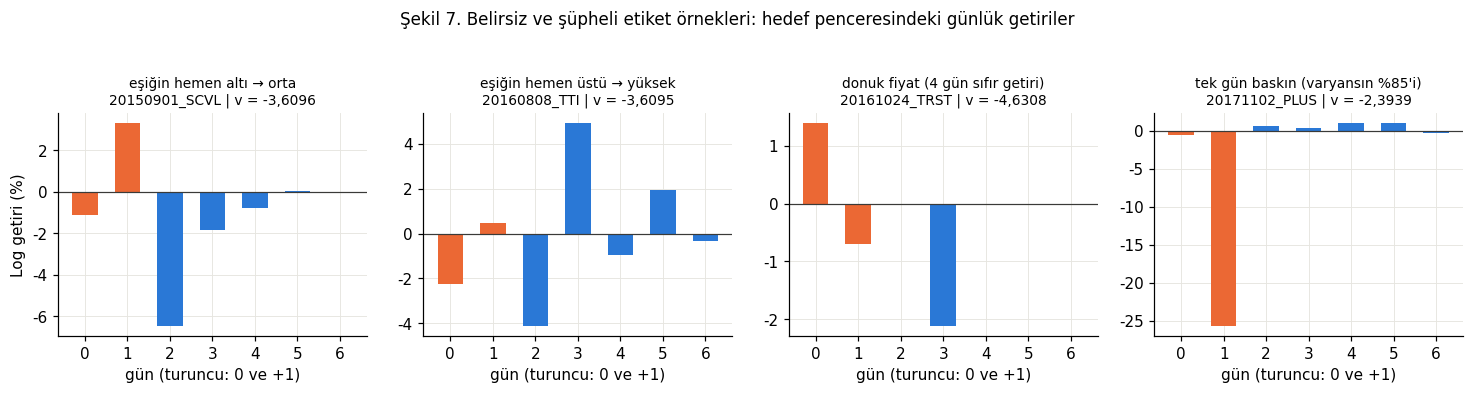

Eşiğin iki yanındaki çağrıların v farkı: 0.00014 (eşik -3.6096)


In [18]:
h0 = 100 * pencere[pencere.gun.between(0, 6)].pivot(index="klasor", columns="gun", values="getiri")
alt_ = tablo[tablo.v <= esik[1]].v.idxmax()      # üst eşiğin hemen altı → orta
ust_ = tablo[tablo.v > esik[1]].v.idxmin()       # üst eşiğin hemen üstü → yüksek
donuk = sifir.idxmax()                           # hedef penceresinde en çok sıfır getirili çağrı
baskin = pay.idxmax()                            # varyansı en çok tek güne yığılmış çağrı
ornek = [(alt_, "eşiğin hemen altı → orta"), (ust_, "eşiğin hemen üstü → yüksek"),
         (donuk, f"donuk fiyat ({int(sifir[donuk])} gün sıfır getiri)"), (baskin, f"tek gün baskın (varyansın %{100 * pay[baskin]:.0f}'i)")]
fig, eksen = plt.subplots(1, 4, figsize=(13.5, 3.4))
for ax, (k, baslik) in zip(eksen, ornek):
    r = h0.loc[k]
    ax.bar(r.index, r.values, color=[TURUNCU if g in (0, 1) else MAVI for g in r.index], width=0.6)
    ax.axhline(0, color=KOYU, lw=0.8)
    ax.set_title(f"{baslik}\n{k} | v = {tr(tablo.v[k], 4)}", fontsize=9)
    ax.set_xticks(range(7))
    ax.set_xlabel("gün (turuncu: 0 ve +1)")
    ax.yaxis.set_major_formatter(VIRGUL)
eksen[0].set_ylabel("Log getiri (%)")
fig.suptitle("Şekil 7. Belirsiz ve şüpheli etiket örnekleri: hedef penceresindeki günlük getiriler", y=1.04, fontsize=11)
fig.tight_layout()
kaydet(fig, "f1_07_supheli_etiketler")
plt.show()
print(f"Eşiğin iki yanındaki çağrıların v farkı: {tablo.v[ust_] - tablo.v[alt_]:.5f} (eşik {esik[1]:.4f})")

**Ne gözlendi:** İlk iki panel üst eşiğin iki yanındaki çağrılar: oynaklıkları neredeyse aynı (fark yukarıdaki çıktıda) ama biri "orta", diğeri "yüksek" etiketli. Üçüncü panelde hedef penceresindeki günlerin bir kısmında fiyat hiç değişmemiş; bu, işlem görmeyen bir hisseye ya da veri sağlayıcısındaki donuk bir kayda işaret edebilir. Dördüncü panelde 7 günlük oynaklığın neredeyse tamamı tek bir günden geliyor.

**Neden önemli:** Sınıf sınırları keskin olduğu için eşiğe yakın etiketler gürültülüdür; bu örnekler hatalı değil ama belirsizdir. Donuk fiyat ise gerçek bir veri kalitesi sorunu olabilir ve etiketi yapay biçimde düşürür. Tek gün baskınlığı, etiketin çoğunlukla açıklamaya verilen ilk tepkiyi ölçtüğünü somut olarak gösterir.

**Sonraki aşamaya etkisi:** Faz 2'de donuk fiyatlı çağrılar için bir kural belirlenip (ör. hedef penceresinde en az 3 sıfır getiri) öncesi–sonrası karşılaştırılacak. Eşik gürültüsü, finalde sürekli v ile regresyon ve sınıflandırma sonuçlarını birlikte raporlamanın gerekçesi.

## 6. Eksik modalite analizi (Kriter 4)

In [19]:
eksik = pd.DataFrame([
    {"durum": "metin dosyası yok", "çağrı": int((cagrilar.n_cumle == 0).sum())},
    {"durum": "metin çok kısa (<100 kelime) — fiilen zayıf metin", "çağrı": int((cagrilar.n_kelime < 100).sum())},
    {"durum": "fiyat serisi yok ya da yetersiz", "çağrı": len(cagrilar) - len(eslesen)},
    {"durum": "  ↳ ticker FNSPID'de yok", "çağrı": int((durum.durum == "ticker fiyat verisinde yok").sum())},
    {"durum": "  ↳ dosya kesik / geçmiş yetersiz", "çağrı": int(durum.durum.isin(sira[1:]).sum())},
    {"durum": "iki modalite tam (nihai)", "çağrı": len(eslesen)},
    {"durum": "  ↳ bunlardan metni <100 kelime", "çağrı": int((tablo.n_kelime < 100).sum())},
    {"durum": "  ↳ bunlardan metni ≤5 kelime", "çağrı": int((tablo.n_kelime <= 5).sum())},
])
eksik["%"] = (100 * eksik["çağrı"] / len(cagrilar)).round(1)
eksik

,durum,çağrı,%
0,metin dosyası yok,0,0.0
1,metin çok kısa (<100 kelime) — fiilen zayıf metin,98,2.8
2,fiyat serisi yok ya da yetersiz,417,12.1
3,↳ ticker FNSPID'de yok,411,11.9
4,↳ dosya kesik / geçmiş yetersiz,6,0.2
5,iki modalite tam (nihai),3026,87.9
6,↳ bunlardan metni <100 kelime,83,2.4
7,↳ bunlardan metni ≤5 kelime,20,0.6


**Ele alma stratejisi:** Füzyon modeli iki modaliteye birlikte ihtiyaç duyduğu için ana veri seti *tam vaka* (iki modalite
de mevcut) üzerine kurulur. Fiyatı eksik çağrılar doldurulmaz (fiyat uydurulamaz). Çok kısa metinler Faz 2'de ayrıca
ele alınır (eşik ve etkisi öncesi–sonrası karşılaştırmasıyla). Finalde tek-modalite modelleri, bir modalite yokken
sistemin nasıl davrandığını göstermek için de kullanılabilir. Not: 24 çağrının metni en fazla 5 kelime (19'u yalnız "Thank you."); bunlar fiilen metni eksik çağrılardır ve 20'si eşleşen kümede.

## 7. Temsil gücü ve olası yanlılıklar (Kriter 3)

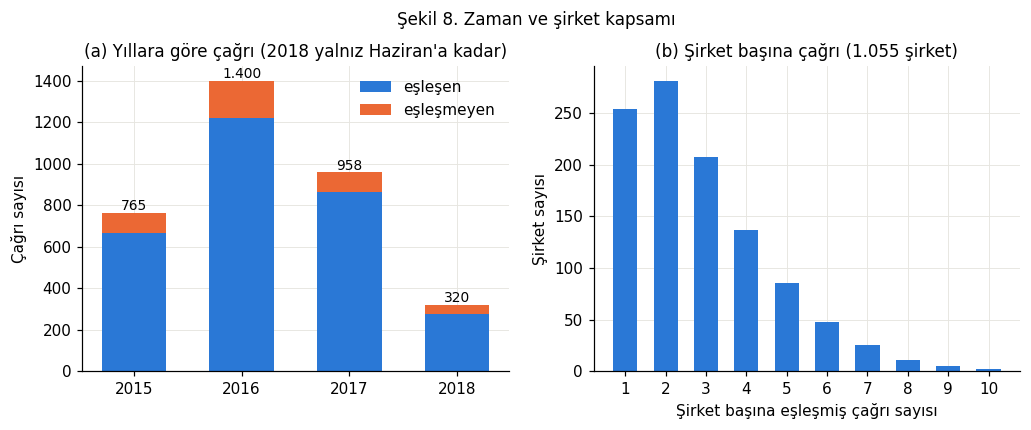

Şirket başına çağrı: ortalama 2.87 | en çok 10 | tek çağrılı şirket: 254 | 1–3 çağrılı: 742 (%70.3)


In [20]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.6))
yy = yil.copy()
a1.bar(yy.index.astype(str), yy.eslesen, color=MAVI, width=0.6, label="eşleşen")
a1.bar(yy.index.astype(str), yy.cagri - yy.eslesen, bottom=yy.eslesen, color=TURUNCU, width=0.6, label="eşleşmeyen")
for i, r in enumerate(yy.itertuples()):
    a1.text(i, r.cagri + 15, tr(r.cagri), ha="center", fontsize=9)
a1.set_ylabel("Çağrı sayısı")
a1.set_title("(a) Yıllara göre çağrı (2018 yalnız Haziran'a kadar)")
a1.legend(frameon=False)
sb = tablo.ticker.value_counts().value_counts().sort_index()
a2.bar(sb.index.astype(str), sb.values, color=MAVI, width=0.6)
a2.set_xlabel("Şirket başına eşleşmiş çağrı sayısı")
a2.set_ylabel("Şirket sayısı")
a2.set_title(f"(b) Şirket başına çağrı ({tr(tablo.ticker.nunique())} şirket)")
fig.suptitle("Şekil 8. Zaman ve şirket kapsamı", y=1.02, fontsize=11)
kaydet(fig, "f1_08_zaman_sirket")
plt.show()
sc = tablo.ticker.value_counts()
print("Şirket başına çağrı: ortalama", round(sc.mean(), 2), "| en çok", sc.max(), "| tek çağrılı şirket:", int((sc == 1).sum()),
      f"| 1–3 çağrılı: {int((sc <= 3).sum())} (%{100 * (sc <= 3).mean():.1f})")

**Ne gözlendi:** Çağrılar 2016'da yoğunlaşıyor (1.400); 2018 yalnız Haziran'a kadar (320). Şirket başına ortalama 2,87 eşleşmiş çağrı var, en çok 10; şirketlerin %70,3'ünün (742) 1–3 çağrısı, 254'ünün tek çağrısı var.

**Neden önemli:** Aynı şirketin birden çok çağrısı var. Yu, Liu ve He (2024), transkript temsillerinin ağırlıkla şirket kimliğini yakaladığını gösteriyor: aynı şirket hem eğitimde hem testte olursa model şirketi ezberleyerek iyi görünebilir. Dönemler de eşit temsil edilmiyor.

**Sonraki aşamaya etkisi:** Faz 4'te şirkete göre gruplu 5 kat (GroupKFold) ve zamana göre bölme birlikte kullanılacak.

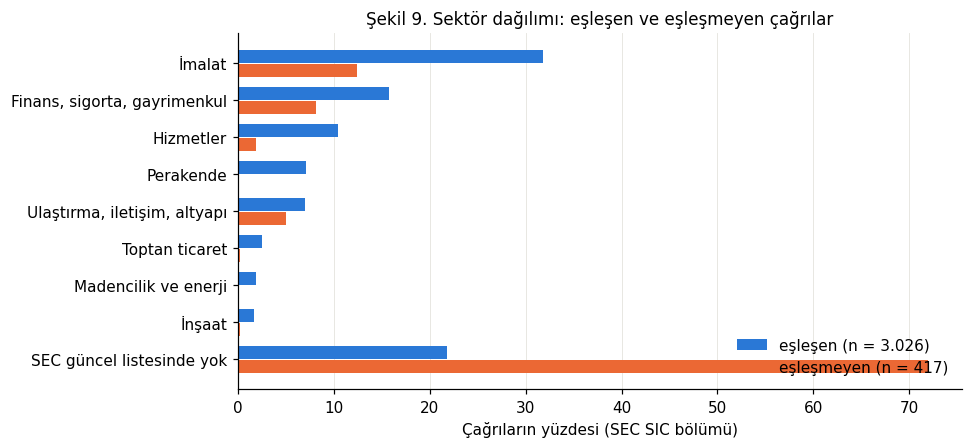

,eşleşen %,eşleşmeyen %
bolum,,
SEC güncel listesinde yok,21.8,71.9
İnşaat,1.7,0.2
Madencilik ve enerji,1.9,0.0
Toptan ticaret,2.5,0.2
"Ulaştırma, iletişim, altyapı",7.0,5.0
Perakende,7.1,0.0
Hizmetler,10.4,1.9
"Finans, sigorta, gayrimenkul",15.8,8.2
İmalat,31.8,12.5


In [21]:
c2["bolum"] = np.where(c2.ticker.map(sirket.cik).isna(), "SEC güncel listesinde yok",
                       c2.ticker.map(sirket.bolum).fillna("SIC kodu yok"))
pay_es = 100 * c2[c2.eslesti].bolum.value_counts(normalize=True)
pay_yok = 100 * c2[~c2.eslesti].bolum.value_counts(normalize=True)
sektor = pd.DataFrame({"eşleşen %": pay_es, "eşleşmeyen %": pay_yok}).fillna(0).sort_values("eşleşen %")
digeri = [i for i in sektor.index if i in ("SEC güncel listesinde yok", "SIC kodu yok")]
sektor = pd.concat([sektor.loc[digeri], sektor.drop(index=digeri)])
fig, ax = plt.subplots(figsize=(8.5, 4.2))
y = np.arange(len(sektor))
ax.barh(y + 0.19, sektor["eşleşen %"], height=0.36, color=MAVI, label=f"eşleşen (n = {tr(c2.eslesti.sum())})")
ax.barh(y - 0.19, sektor["eşleşmeyen %"], height=0.36, color=TURUNCU, label=f"eşleşmeyen (n = {tr((~c2.eslesti).sum())})")
ax.set_yticks(y, sektor.index)
ax.set_xlabel("Çağrıların yüzdesi (SEC SIC bölümü)")
ax.legend(frameon=False, loc="lower right")
ax.grid(axis="y", visible=False)
ax.set_title("Şekil 9. Sektör dağılımı: eşleşen ve eşleşmeyen çağrılar")
kaydet(fig, "f1_09_sektor")
plt.show()
sektor.round(1)

**Ne gözlendi:** Eşleşen çağrılarda en büyük sektör imalat (%31,8), ardından finans-sigorta-gayrimenkul (%15,8) ve hizmetler (%10,4). Eşleşen çağrıların %21,8'inin şirketi SEC'in bugünkü listesinde yok, sektörü bilinmiyor. Eşleşmeyen çağrılarda bu oran %71,9.

**Neden önemli:** Veri tek bir sektöre sıkışmamış. Ama sektör bilgisi eşleşen çağrıların beşte birinde eksik ve eşleşmeyenler büyük ölçüde artık listelenmeyen şirketler (4.1'deki hayatta kalma yanlılığını destekliyor). SIC bölümleri kaba bir sınıflamadır: "imalat" ilaç, yarı iletken ve gıda gibi çok farklı işleri kapsar.

**Sonraki aşamaya etkisi:** EDA'da oynaklığın sektöre göre farkına bakılacak; sektör, modelde isteğe bağlı bir bağlam özelliği olabilir.

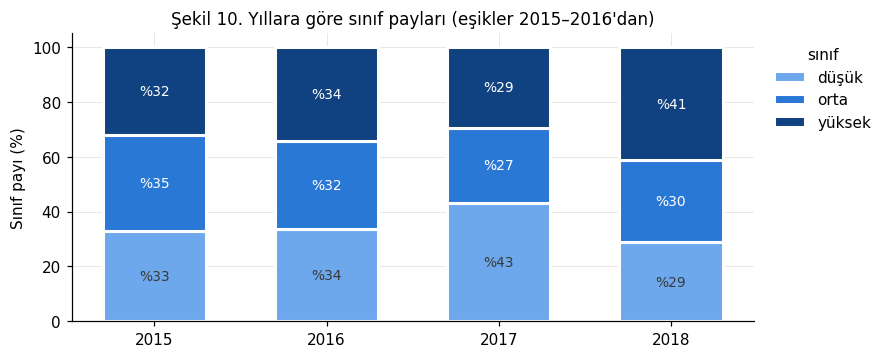

sinif,düşük,orta,yüksek
tarih,,,
2015,33.0,35.0,32.0
2016,33.5,32.4,34.1
2017,43.2,27.5,29.4
2018,28.8,29.9,41.4


In [22]:
pay_yil = pd.crosstab(tablo.tarih.dt.year, tablo.sinif, normalize="index").mul(100).rename(columns=dict(enumerate(etiket.SINIF_ADLARI)))
fig, ax = plt.subplots(figsize=(8, 3.4))
alt = np.zeros(len(pay_yil))
for c, ad in enumerate(etiket.SINIF_ADLARI):
    ax.bar(pay_yil.index.astype(str), pay_yil[ad], bottom=alt, color=SINIF_RENK[c], width=0.6, label=ad,
           edgecolor="white", linewidth=2)
    for i, (b, h_) in enumerate(zip(alt, pay_yil[ad])):
        ax.text(i, b + h_ / 2, f"%{h_:.0f}", ha="center", va="center", fontsize=9, color="white" if c > 0 else KOYU)
    alt += pay_yil[ad].to_numpy()
ax.set_ylabel("Sınıf payı (%)")
ax.legend(title="sınıf", frameon=False, bbox_to_anchor=(1.01, 1), loc="upper left")
ax.set_title("Şekil 10. Yıllara göre sınıf payları (eşikler 2015–2016'dan)")
kaydet(fig, "f1_10_yil_sinif")
plt.show()
pay_yil.round(1)

**Ne gözlendi:** 2015 ve 2016'da sınıflar yaklaşık eşit. 2017'de düşük oynaklık payı %43'e çıkıyor; 2018'de (Ocak–Haziran) yüksek oynaklık payı %41.

**Neden önemli:** Oynaklık yalnız şirkete değil piyasa dönemine de bağlı (zaman yanlılığı). Piyasa geneli oynaklığı, metin ile hedef arasındaki ilişkiyi karıştıran bir etken olabilir.

**Sonraki aşamaya etkisi:** EDA'da piyasa geneli oynaklığı (SPY'nin gerçekleşen oynaklığı) ile sınıf payları birlikte incelenecek. Zaman bölmesinde test dönemi farklı bir piyasa rejimine denk geldiği için skorlar düşebilir.

### Temsil gücü özeti (Kriter 3)

| Boyut | Durum | Olası yanlılık |
|---|---|---|
| Kaynak / evren | S&P 1500 şirketleri (MAEC), yalnız ABD, İngilizce | Küçük ve ABD dışı şirketlere genelleme sınırlı |
| Zaman | 2015-02 – 2018-06; 2016 yoğun, 2018 yarım yıl | Tek bir piyasa dönemi; sınıf payları yıla göre kayıyor (Şekil 10) |
| Şirket | 1.055 şirket, şirket başına 1–10 çağrı | Aynı şirketin çağrıları birbirine bağımlı (Faz 4'te gruplu bölme) |
| Sektör | En büyük pay imalat (%31,8); %21,8'inde sektör bilinmiyor | Sektör bilgisi eksik; SIC bölümleri kaba |
| Hayatta kalma | Eşleşmeyenlerin çoğu bugün listelenmeyen şirketler | Sonradan borsadan çıkan şirketler eksik temsil ediliyor |
| Konuşmacı | Yalnız yönetim konuşması; analist soruları yok | Metin, çağrının tamamını temsil etmiyor |

## 8. Veri özeti ve kayıt

In [23]:
tablo["ad_geciyor"] = tablo.ad_geciyor.astype("boolean")
tablo["girdi_eksik_gun"] = uc.girdi_eksik_gun
tablo["bolum"] = tablo.ticker.map(sirket.bolum)
tablo.reset_index().to_parquet(ISLENMIS / "cagrilar_eslesmis.parquet", index=False)
pencere.to_parquet(ISLENMIS / "fiyat_pencereleri.parquet", index=False)
dokum.to_csv(CIKTI / "f1_veri_kaybi_dokumu.csv", index=False)
siniflar.to_csv(CIKTI / "f1_sinif_dagilimi.csv")
sektor.round(2).to_csv(CIKTI / "f1_sektor_dagilimi.csv")

veri_ozeti = pd.Series({
    "MAEC ham çağrı": len(cagrilar),
    "MAEC şirket": cagrilar.ticker.nunique(),
    "FNSPID fiyat dosyası": len(fiyat_yollari),
    "eşleşen çağrı (iki modalite tam)": len(eslesen),
    "eşleşen şirket": tablo.ticker.nunique(),
    "eşleşme oranı %": round(100 * len(eslesen) / len(cagrilar), 1),
    "düşen: ticker yok": int((durum.durum == "ticker fiyat verisinde yok").sum()),
    "düşen: dosya kesik / geçmiş yetersiz": int(durum.durum.isin(sira[1:]).sum()),
    "sınıf düşük / orta / yüksek (tümü)": "/".join(map(str, siniflar.iloc[:3, 0])),
    "sınıf düşük / orta / yüksek (eğitim ≤2016)": "/".join(map(str, siniflar.iloc[:3, 1])),
    "metni <100 kelime (eşleşenlerde)": int((tablo.n_kelime < 100).sum()),
}, name="değer")
veri_ozeti.to_csv(CIKTI / "f1_veri_ozeti.csv")
veri_ozeti.to_frame()

,değer
MAEC ham çağrı,3443
MAEC şirket,1213
FNSPID fiyat dosyası,7693
eşleşen çağrı (iki modalite tam),3026
eşleşen şirket,1055
eşleşme oranı %,87.9
düşen: ticker yok,411
düşen: dosya kesik / geçmiş yetersiz,6
sınıf düşük / orta / yüksek (tümü),1081/948/997
sınıf düşük / orta / yüksek (eğitim ≤2016),629/628/629


In [24]:
modalite = pd.DataFrame([
    {"modalite": "Metin (MAEC text.txt)", "ham": f"{tr(len(cagrilar))} çağrı",
     "kullanılabilir": f"{tr((cagrilar.n_kelime > 5).sum())} çağrı (≤5 kelimelik {int((cagrilar.n_kelime <= 5).sum())} metin fiilen boş)"},
    {"modalite": "Zaman serisi (FNSPID)", "ham": f"{tr(len(fiyat_yollari))} hisse dosyası",
     "kullanılabilir": f"{tr(len(eslesen))} çağrı için tam 61+7 günlük pencere ({tr(tablo.ticker.nunique())} şirket)"},
    {"modalite": "Eşleşmiş (iki modalite tam)", "ham": f"{tr(len(cagrilar))} çağrı",
     "kullanılabilir": f"{tr(len(eslesen))} çağrı (%{tr(100 * len(eslesen) / len(cagrilar), 1)}); metni >5 kelime olan: {tr((tablo.n_kelime > 5).sum())}"},
]).set_index("modalite")
modalite.to_csv(CIKTI / "f1_modalite_sayilari.csv")
modalite

,ham,kullanılabilir
modalite,,
Metin (MAEC text.txt),3.443 çağrı,3.419 çağrı (≤5 kelimelik 24 metin fiilen boş)
Zaman serisi (FNSPID),7.693 hisse dosyası,3.026 çağrı için tam 61+7 günlük pencere (1.055 şirket)
Eşleşmiş (iki modalite tam),3.443 çağrı,"3.026 çağrı (%87,9); metni >5 kelime olan: 3.006"


## 9. Kısa değerlendirme

**Öne çıkan bulgular**
1. İki modalite 3.026 çağrıda (%87,9; 1.055 şirket) eşleşti. Ders şartı (3 sınıf, sınıf başına ≥ 150, toplam ≥ 500) fazlasıyla sağlanıyor: 1.081 / 948 / 997.
2. Eşleşme üç bağımsız kanıtla doğrulandı: olay günü sıçraması (Şekil 3), şirket adı kontrolü (kendi adı %64,1, başka şirketin adı %3,7) ve gerçek örnekler (Şekil 4).
3. Hedef büyük ölçüde açıklamaya verilen ilk tepkiyi ölçüyor: 7 günlük varyansın medyan %53'ü tek bir günden, çoğunlukla gün 0 ya da +1'den geliyor.

**Sınırlılıklar**
- Metin tam transkript değil, yönetim konuşması (analist soruları yok); 24 çağrıda metin fiilen boş.
- Hayatta kalma yanlılığı: eşleşmeyen şirketlerin çoğu bugün listelenmiyor.
- Çağrı saati yok: kapanış sonrası çağrılarda gün 0 getirisi çağrı öncesi saatleri de içerir.
- Sınıf payları zamanla kayıyor (2017 sakin, 2018 oynak).
- Fiyatların kökeni Yahoo Finance; veri yeniden dağıtılmıyor, yalnız indirme kodu paylaşılıyor.

**Sonraki adım (Faz 2: temizlik ve ön işleme):** çok kısa metinler, donuk fiyatlı ve uç oynaklıklı çağrılar; metin temizliği (`<UNK>`, boş satırlar) ve fiyat serisinin modele hazırlanması; en az iki öncesi–sonrası karşılaştırma.